## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [44]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

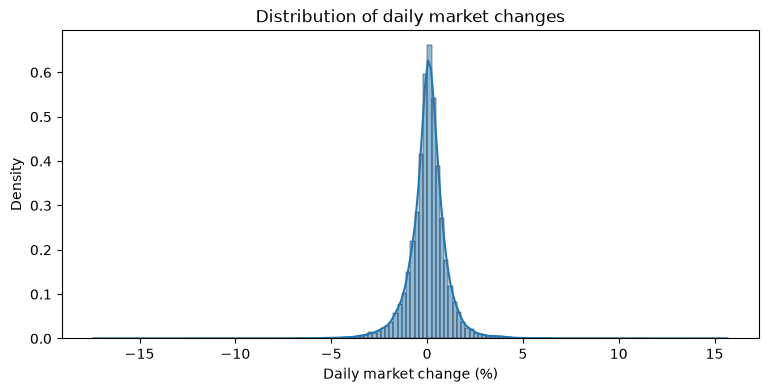

In [45]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

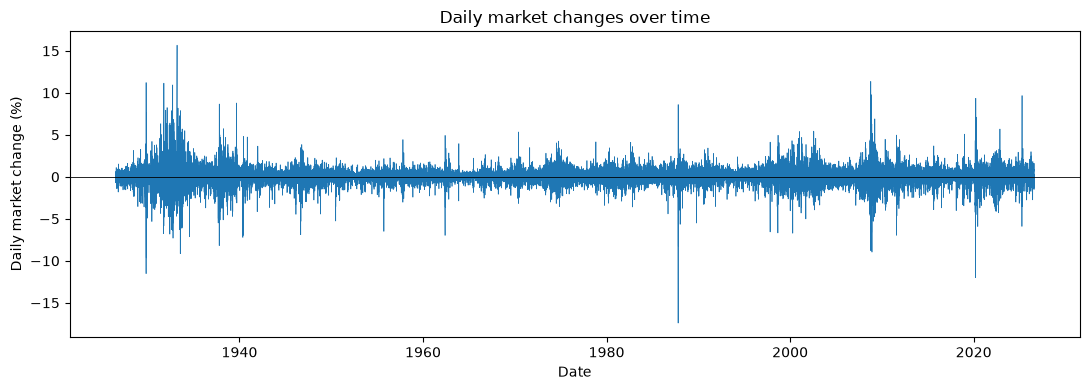

In [46]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [47]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
df['direction_t'] = pd.Categorical(np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
                                   categories=direction_categories)
df['direction_t']

0                 Up
1                 Up
2                 Up
3                 Up
4                 Up
            ...     
26291             Up
26292             Up
26293    Down / flat
26294             Up
26295             Up
Name: direction_t, Length: 26296, dtype: category
Categories (2, object): ['Down / flat', 'Up']

In [48]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [49]:
df[["direction_t", "direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [50]:
pd.crosstab(df["direction_t"], df["direction_tp1"], normalize=True, margins=True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


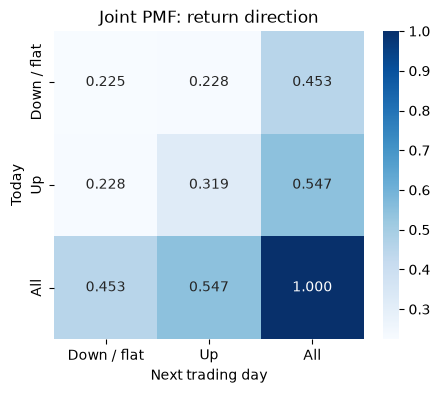

In [51]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["direction_t"], df["direction_tp1"], normalize=True, margins=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [52]:
# Plot the conditional PMF
pd.crosstab(df["direction_t"], df["direction_tp1"], normalize='index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


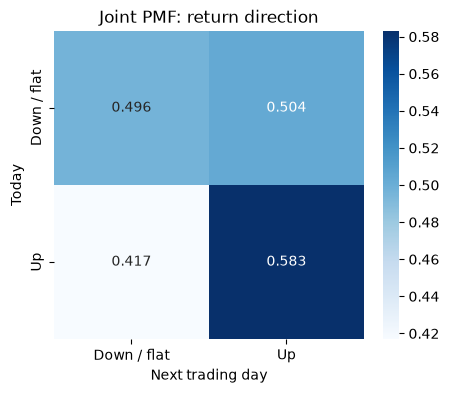

In [53]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["direction_t"], df["direction_tp1"], normalize='index'),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

**Whatever today was, there is a 0.547 probability tomorrow will be up, so up transitions have a slightly higher probability and we could say are more common.**

**Up transitions are more common when today is an Up day and tomorrow is an Up day (0.583).**

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [54]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=return_categories)


In [55]:
df['return_bin']

0         Near zero
1        Small gain
2        Small gain
3         Near zero
4        Small gain
            ...    
26291    Small gain
26292    Small gain
26293    Large loss
26294    Large gain
26295    Small gain
Name: return_bin, Length: 26296, dtype: category
Categories (5, object): ['Large loss' < 'Small loss' < 'Near zero' < 'Small gain' < 'Large gain']

In [56]:
#make y_t and y_tp1 columns for the return bins
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [57]:
df['y_t'] = df['return_bin']
df['y_tp1'] = df['y_t'].shift(-1)

In [58]:
pd.crosstab(df["y_t"], df["y_tp1"], normalize=True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

Small gain    9785

Small loss    7452

Near zero     3441

Large gain    2859

Large loss    2759

**Large loss and large gains are least common while small gains and small losses are most common.**

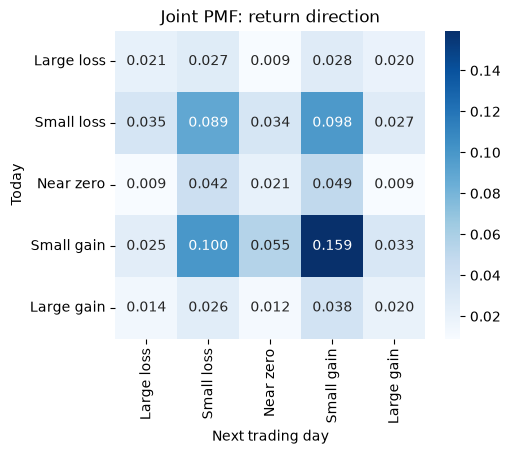

In [59]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

**We have the most days fall into small gains. Because it takes up more of our data, we are most likely to have a small gain transition than the other categories which is corroborated by the joint probability crosstab.**

In [60]:
#conditional PMF 
pd.crosstab(df["y_t"], df["y_tp1"], normalize='index', margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281
All,0.104925,0.283400,0.130823,0.372124,0.108728


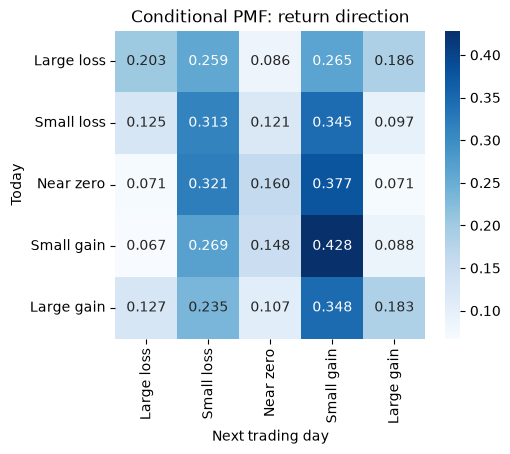

In [61]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize='index'),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

**Small loss and small gain are the most likely future states. Today does not give us that much information about tomorrow because each row follows the same pattern.** 

**We can get a little better of a guess than a uniform mass function, but not by much. A uniform PMF would have a probability of 0.2 over all transitions. The numbers in our heatmap are not exactly 0.2, but for our two most common future states (small loss and small gain), they hover around that value.**

**We can expect that the marginal of tomorrow would be fairly similar to the conditional probability of tomorrow given today. This steers us towards weak dependence, or near-independence.**

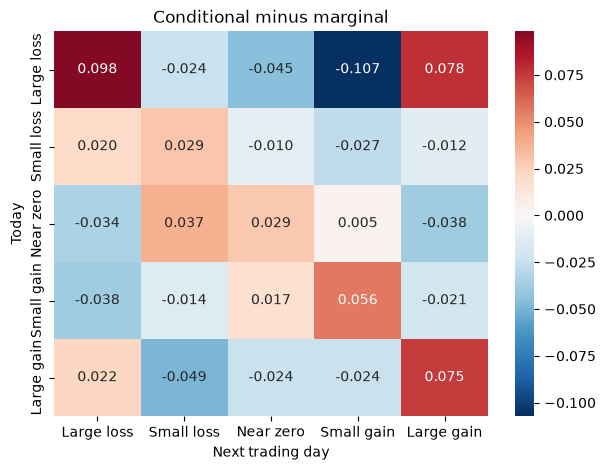

In [62]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df["y_t"], df["y_tp1"], normalize=True).sum(axis=0)

next_state_pmf

# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize='index').sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional minus marginal')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

**Large loss to large loss, large gain to large gain, and large loss to large gains are more likely than independence predicts.**

**A transition from large loss to small gain is less likely to occur than independence predicts.**

**Knowing today's state gives us a bit of insight into tomorrow if we are dealing with extremes. The heatmap shows our predictions will be slightly different than a uniform PMF. Comparing the uniform PMF probability 0.2 to the conditional is different because by comparing the marginal we are testing the magnitude of independence/dependence. 0.2 would be random guessing or, in other words, a base rate.**

In [63]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')["market_return_pct_tp1"].describe()

/var/folders/yv/g_9pwhts5jvb7m7p1fvjvfzr0000gp/T/ipykernel_80588/2779646233.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


**If there was a large loss today, we would expect a 0.03% loss tomorrow**

**If there was a small loss today, we would expect a 0.04% loss tomorrow**

**If there was near zero loss today, we would expect a 0.02% gain tomorrow**

**If there was a small gain today, we would expect a 0.11% gain tomorrow**

**If there was a large gain today, we would expect a 0.16% gain tomorrow**

**Min/max values appear the largest in the extremes (large loss/large gain) as well as small loss. This means that large loss, large gain, and small loss have the most volatility/variance. Near 0 and small gain are similar to each other.**

**Since variance is high in large loss and large gain as we stated above, the standard deviations are also high.**

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [64]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


<Axes: xlabel='y_tp1', ylabel='y_t'>

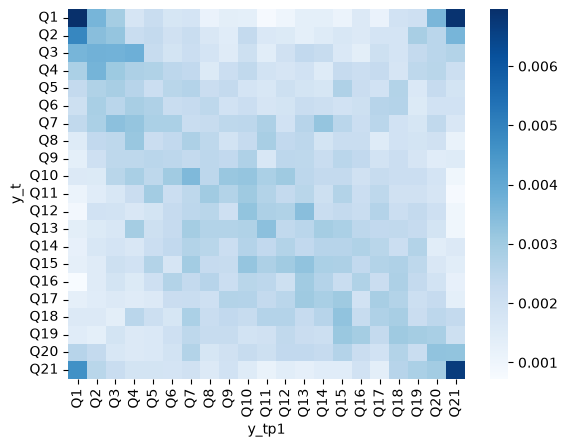

In [65]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df["y_t"], df["y_tp1"],
    normalize=True
)

sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

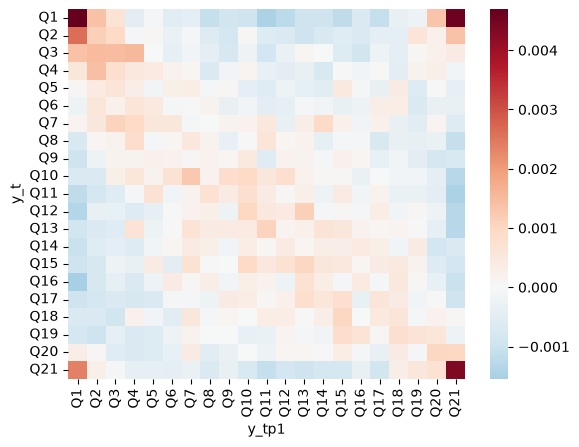

In [66]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**The extremes show a higher probability in both heatmaps. When we subtract out the uniform, we see the volatile relationships between states stay that way.**

<Axes: xlabel='y_tp1', ylabel='y_t'>

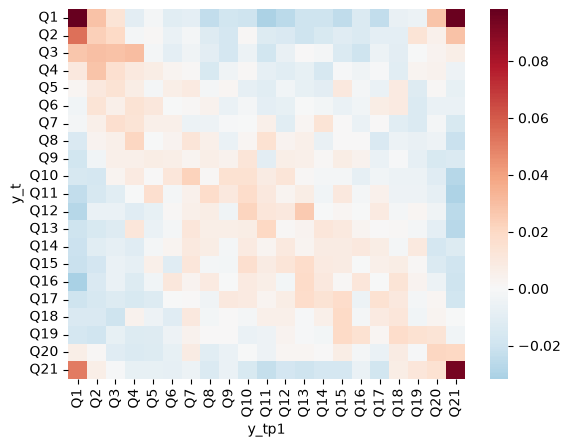

In [67]:
# compute and plot the conditional
quantile_conditional = pd.crosstab(
    df["y_t"], df["y_tp1"],
    normalize='index'
)
sns.heatmap(quantile_conditional - 1/bins, cmap='RdBu_r', center=0)

<Axes: xlabel='y_tp1', ylabel='y_t'>

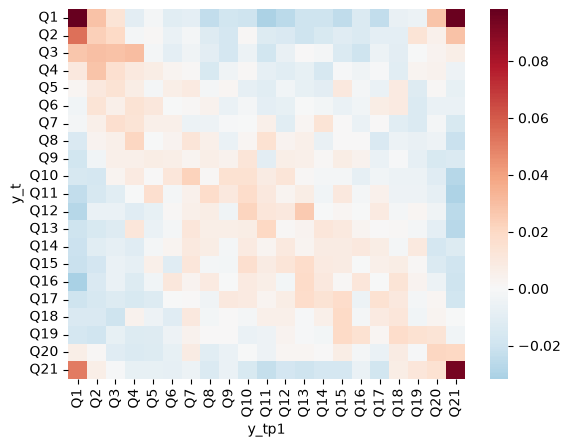

In [69]:
# Subtract 1/21 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

sns.heatmap(quantile_conditional - 1/bins, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Once again when we subtract out the uniform, we see the volatile relationships between states stay that way, telling us there is some non-uniform behavior going on.**

In [70]:
# compute the next day's min, mean, and max conditional on each bin
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')["market_return_pct_tp1"].describe()

/var/folders/yv/g_9pwhts5jvb7m7p1fvjvfzr0000gp/T/ipykernel_80588/46792200.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Q1,1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
Q2,1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
Q3,1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
Q4,1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
Q5,1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
Q6,1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
Q7,1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
Q8,1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
Q9,1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


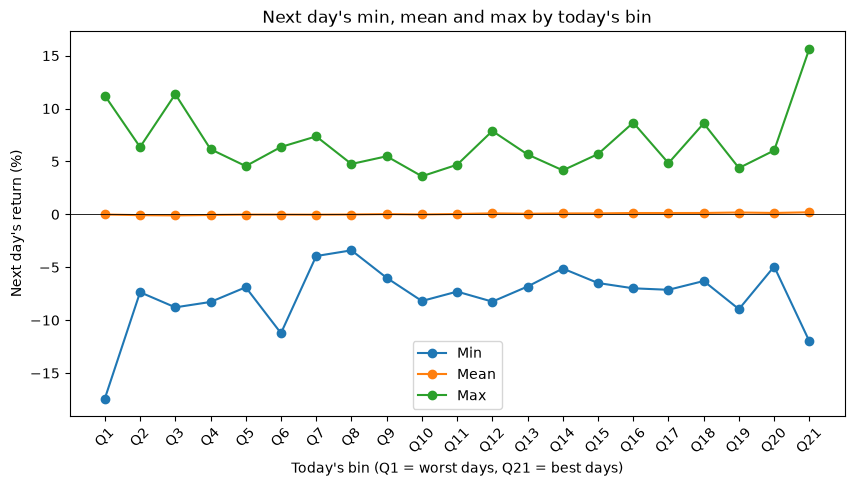

In [ ]:
#plot as lines on a graph against the bins
# We used Claude to help generate this graph
summary = df.groupby('y_t', observed=True)['market_return_pct_tp1'].describe()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(summary.index.astype(str), summary['min'],  marker='o', label='Min')
ax.plot(summary.index.astype(str), summary['mean'], marker='o', label='Mean')
ax.plot(summary.index.astype(str), summary['max'],  marker='o', label='Max')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's bin (Q1 = worst days, Q21 = best days)",
       ylabel="Next day's return (%)",
       title="Next day's min, mean and max by today's bin")
ax.legend()
plt.xticks(rotation=45)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**We can see that all the means seem to hover around 0. We also further confirm that the extreme states are more volatile and tend to have a great magnitude of min/max.**

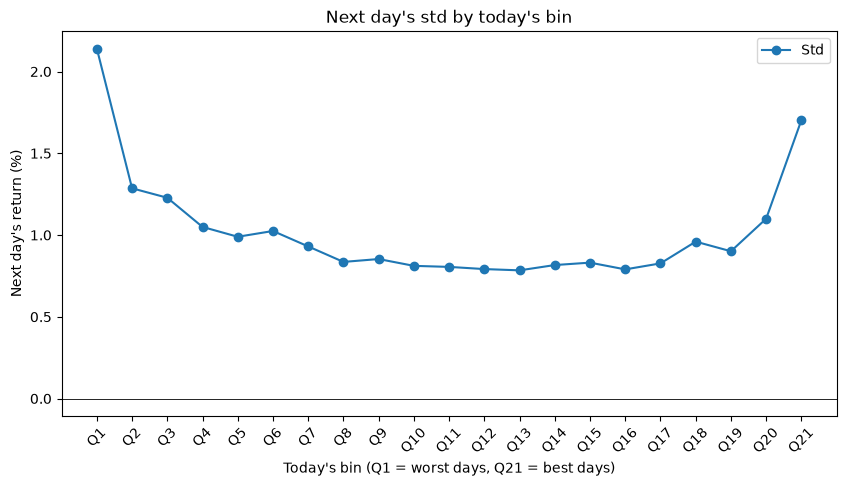

In [72]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(summary.index.astype(str), summary['std'],  marker='o', label='Std')

ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's bin (Q1 = worst days, Q21 = best days)",
       ylabel="Next day's return (%)",
       title="Next day's std by today's bin")
ax.legend()
plt.xticks(rotation=45)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

**Standard deviation is higher among the extreme states/bins (Q1 and Q21). This is expected because they are more volatile and so, are more varied in their expectation**

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

**It's not as easy as you may think. The following are our conclusions:**

* We cannot easily predict our returns on any given day, but we can get a sense of common transitions between states (gains/losses). As we saw with the extreme states being more volatile, but seemingly dependent, we can say that if we are in an extreme state we are more likely to transition to another extreme state, but we can't be certain about whether we would lose or gain or the quantity at which we would do so. Today does not give us much information about tomorrow for less extreme states. As we saw their min/max values, they stay similar to each other across states and, when subracting conditional - marginal, we saw that less extreme states were closer to 0 and so there is evidence to say there is weak dependence between states (near independence), making prediction difficult.

* Overall, it's not easy to predict less extreme states, but can be easier to predict extreme states and transitions between extreme states. In no scenario is it easy to quanitfy our returns.